# Problem set 8: Random numbers and simulation - comments/solutions

# Programming for Economists Autumn 2026: Class 3
**Matias BF Hall**

**Table of contents**<a id='toc0_'></a>    
- 1. [RNG Warm-up (Reproducibility Basics)](#toc1_)    
- 2. [Drawing from a Pareto distribution](#toc2_)    
- 3. [One worker: employed or unemployed?](#toc3_)    
- 4. [Many workers: the unemployment rate](#toc4_)    
- 5. [Unemployment flows without random numbers](#toc5_)    
- 6. [Optional: diversification with two stocks](#toc6_)    

<!-- vscode-jupyter-toc-config
	numbering=true
	anchor=true
	flat=false
	minLevel=2
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

In [2]:
import numpy as np
import matplotlib.pyplot as plt

## 1. <a id='toc1_'></a>[RNG Warm-up (Reproducibility Basics)](#toc0_)

**Goal.** Create reproducible draws; understand *seed vs stream*.

- Create `rng = np.random.default_rng(2025)`.
- Draw 5 uniforms and 5 normals.
- Re-create the same sequence by constructing a **new** generator with the same seed.
- Show that **calling the same generator twice** advances the stream (different outputs).

In [3]:
# Starter (safe to run)
rng = np.random.default_rng(2025)
u1 = rng.random(5)
z1 = rng.standard_normal(5)

rng_same = np.random.default_rng(2025)
# Task: Reproduce the first draws from the same seed
u2 = rng_same.random(5)
z2 = rng_same.standard_normal(5)

# Stream progression (same generator again)
u_next = rng.random(5)
z_next = rng.standard_normal(5)

# Print first draws
print("First uniform draws u1:", u1)
print("First standard normal draws z1:", z1)

# Check that u1 equals u2 and z1 equals z2
print("u1 equals u2:", np.allclose(u1, u2))
print("z1 equals z2:", np.allclose(z1, z2))

# Print the next draws
print("Next uniform draws:", u_next)
print("Next standard normal draws:", z_next)


# As we see the draws where we refresh the generator with the same seed are identical
# The next draws continue the sequence from the first generator
# That is we have moved down the stream after the first 5 draws,
# so even though we started at the same seed, the next draws are different

First uniform draws u1: [0.99445781 0.38200974 0.82714801 0.83725528 0.97580901]
First standard normal draws z1: [ 0.7653914  -0.75970935  0.26699619  0.70178085  0.29212132]
u1 equals u2: True
z1 equals z2: True
Next uniform draws: [0.38954302 0.23021956 0.16696115 0.15343643 0.9740917 ]
Next standard normal draws: [-0.3924407  -0.67731696  2.93601077 -0.66462723  1.25746344]


## 2. <a id='toc2_'></a>[Drawing from a Pareto distribution](#toc0_)

Wealth, firm sizes and city sizes have a few very large values: a **fat tail**. The Pareto distribution is the classic model for this. With shape parameter $b$ and minimum value 1, the share of draws above $x$ is

$$P(X>x) = x^{-b},\qquad x\ge 1.$$

**Tasks.**
1. Draw 10,000 numbers from a Pareto distribution with $b=2$ using a local generator. `rng.pareto(b, size) + 1.0` gives the version with minimum 1.
2. Plot a histogram of `np.log(draws)`. Why is the log easier to look at than the draws themselves?
3. What share of draws lies above 2, 5 and 10? Compare with the formula $x^{-b}$.

*Optional:* plot the share of draws above $x$ against $x$ on log-log axes (`ax.loglog`). For a Pareto distribution it is a straight line.

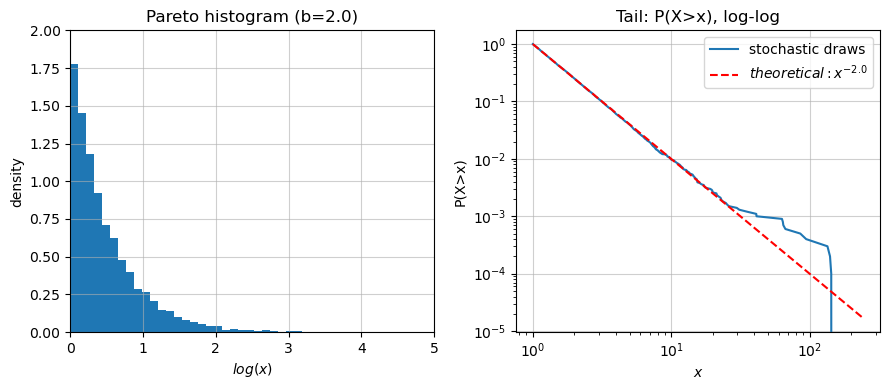

In [ ]:
# define the pareto variables
size = 10_000
b = 2.0

# restart rng for reproducibility
rng = np.random.default_rng(2025)
# generate pareto draws using hint above
pareto_draws = rng.pareto(b, size) + 1.0

# create plot
fig, axs = plt.subplots(1, 2, figsize=(9, 4), sharex=False) # create two surfaces to plot on using 1 row and 2 columns. They don't share the x-axis.

# histogram, created to look like the lecture solution
axs[0].hist(np.log(pareto_draws), bins=50, density=True) # we select the first column using [0]
axs[0].set_title(f'Pareto histogram (b={b})')
axs[0].set_xlabel(f'$log(x)$')
axs[0].set_ylabel('density')
axs[0].set_xlim(0, 5)
axs[0].set_ylim(0, 2)
axs[0].grid(True, alpha=0.6)

##### Optional: #####
# plot the tail of the distribution, which is the probability that a draw is greater than x. 
# This is done by sorting the draws and plotting the rank of each draw against its value. The rank is 1 - (rank / size), which goes from 1 to 0 as the rank goes from 1 to size. The theoretical tail is given by x^(-b).
# tail, created to look like the lecture solution
draws_sorted = np.sort(pareto_draws) # sort draws so the line does not jump
axs[1].loglog(draws_sorted, 1 - np.arange(1, size + 1) / size, label='stochastic draws') # the y-value is created by the rank of the draw, which is 1 - (rank / size). The y-value goes from 1 to 0 as the rank goes from 1 to size. 
axs[1].loglog(draws_sorted, draws_sorted**(-b), label=f'$theoretical: x^{{-{b}}}$', linestyle='--',c='red') # theoretical tail
axs[1].set_title(f'Tail: P(X>x), log-log')
axs[1].set_xlabel(f'$x$')
axs[1].set_ylabel('P(X>x)')
axs[1].grid(True, alpha=0.6)
axs[1].legend()
fig.tight_layout()
plt.show();

## 3. <a id='toc3_'></a>[One worker: employed or unemployed?](#toc0_)

**Goal.** Simulate a single worker who is hit by random shocks each period (think of a period as a month):

- If **Employed** ($E$), a bad shock causes separation to **Unemployment** ($U$) with probability $s$.
- If **Unemployed** ($U$), a good shock leads to job finding back to $E$ with probability $f$.

Encode $0=E$, $1=U$ so that the average of the path is directly the unemployment share.

**Intuition.** Each period a worker is in one state. A *transition probability* tells you how likely it is to switch next period ($s$ is the job-separation rate, $f$ the job-finding rate). Simulating just means: draw a uniform $u\sim U[0,1]$ and compare it to the relevant probability to decide the next state.

**Task: Implement the following**

1. Pick inputs: horizon $T$, separation probability $s$, job-finding probability $f$, initial state $s_0\in\{0,1\}$ (encode $0=E$, $1=U$), and a seed.
2. For each period $t=0,\dots,T-1$, draw one uniform $\epsilon_t\sim U[0,1]$ and apply:
   - If in $E$: set next state to $U$ if $\epsilon_t<s$, else stay in $E$.
   - If in $U$: set next state to $E$ if $\epsilon_t<f$, else stay in $U$.
3. Store the whole path of length $T+1$ and report the share of time in $U$ (the mean, since $U=1$).

**Hints**
- Use $0=E$, $1=U$ so averages give unemployment directly.
- One fresh random draw per period.
- Start small ($T=20$) to print and check; then scale up.
- Set a seed for reproducibility while debugging.

In [5]:
# Set the number of periods, and workers, T and N
# Also defining E and U, and s, f and s0
T = 1_000
N = 1
E = 0.0
U = 1.0
s = 0.02
f = 0.3
s0 = 0


# This is a very basic and slow function where I loop over each period and each worker
# See the exercise solution for a more efficient vectorized version
def unemployment_simulation(T, N, s, f,s0):
    # Simulate productivity draws for N workers over T periods
    # Initialize random number generator for replicability
    rng = np.random.default_rng(2026)
    draw = rng.random((T, N))

    # initialise state arrays with the initial state s0
    states = np.full((T+1, N),s0)

    # we loop over each period
    for t in range(T):
        # and each worker
        for n in range(N):
            if states[t, n] == E:
                # if employed, check if they become unemployed
                if draw[t, n] < s:
                    states[t+1, n] = U
                else:
                    states[t+1, n] = E
            else:
                # if unemployed, check if they become employed
                if draw[t, n] < f:
                    states[t+1, n] = E
                else:
                    states[t+1, n] = U
    return states, draw

# Run the simulation
states, draws = unemployment_simulation(T, N, s, f,s0)

# Print the states and draws and unemployment rate
print(f'First 10 shocks (uniform): {np.round(draws[:10, 0], 3)}')
print(f'First 10 states: {np.round(states[:10, 0], 4)}')
print(f'unemployment rate: {np.mean(states):.4f}')


First 10 shocks (uniform): [0.179 0.64  0.467 0.371 0.355 0.791 0.905 0.177 0.653 0.298]
First 10 states: [0 0 0 0 0 0 0 0 0 0]
unemployment rate: 0.0579


## 4. <a id='toc4_'></a>[Many workers: the unemployment rate](#toc0_)

Simulate $N=10{,}000$ workers in parallel for $T=500$ periods (one uniform draw per worker per period) and track the **unemployment rate**, the share of workers in $U$, over time. Keep the sizes moderate: 10,000 workers × 500 periods is already 5 million random draws.

All workers start employed, so the first periods are not typical. This start-up phase is the **burn-in**; leave out the first 100 periods before averaging. With many workers, the average unemployment rate should come close to

$$u^*=\frac{s}{s+f}.$$

Plot the unemployment rate against time.

In [ ]:
# set the number of periods, and workers, T and N
# we want at least 1000 periods to have a long burn-in period, and N is set as suggested.
# I don't set T higher than 2000 due to the inefficiency of the function above, but it is feasible to set T higher if you use a vectorized version of the function.
T = 2_000
N = 50_000

# Use the function above
states, draws = unemployment_simulation(T, N, s, f, s0)

# compute the average unemployment rate over time, axis one so we get the average across all workers for each period
u_rate_periods = np.mean(states[1000+1:,:], axis=1) # plut one since index 0 is the intial state, and not part of the burn-in period.

# compute theoretical unemployment rate:
u_theoretical = s / (s + f)

# prints
print(f'First 10 unemployment rates: {np.round(np.mean(states[:10, :], axis=1), 4)}')
print(f'Last 10 unemployment rates: {np.round(np.mean(states[-10:, :], axis=1), 4)}')
print(f'Average unemployment rate after burn-in (T>1000): {np.round(np.mean(u_rate_periods), 4)}')
print(f'Theoretical unemployment rate: {np.round(u_theoretical, 4)}')


First 10 unemployment rates: [0.     0.0202 0.0343 0.0431 0.0495 0.0528 0.0562 0.0586 0.06   0.0611]
Last 10 unemployment rates: [0.0611 0.0616 0.0612 0.0618 0.0617 0.0625 0.0627 0.0626 0.0614 0.0619]
Average unemployment rate after burn-in (T>1000): 0.0626
Theoretical unemployment rate: 0.0625


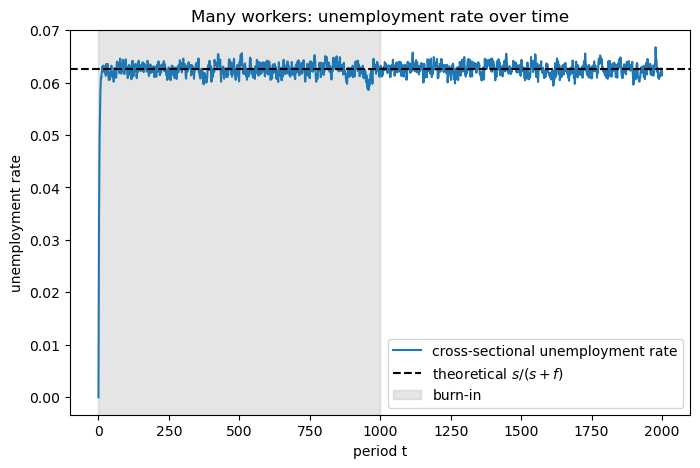

In [7]:
# Plotting the unemployment rate over time, with a burn-in period and the theoretical unemployment rate

# set burn-in period, compute the average unemployment rate over time, create a time vector, and theoretical unemployment rate
burn_in = 1000
u_rate = np.mean(states, axis=1)
t = np.arange(u_rate.size)
pi_star = s / (s + f)

# plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t, u_rate, label='cross-sectional unemployment rate')
ax.axhline(pi_star, ls='--', color='black', label=r'theoretical $s/(s+f)$') # the theoretical unemployment rate plotted as a dashed horisontal line
if burn_in > 0:
    ax.axvspan(0, burn_in, color='grey', alpha=0.2, label='burn-in')
ax.set_xlabel('period t')
ax.set_ylabel('unemployment rate')
ax.set_title('Many workers: unemployment rate over time')
ax.legend()
plt.show()

## 5. <a id='toc5_'></a>[Unemployment flows without random numbers](#toc0_)

With very many workers, the randomness averages out and we can track the unemployment **rate** $u_t$ directly. Each period:

- **inflow:** a share $s$ of the employed, $s\,(1-u_t)$, lose their job;
- **outflow:** a share $f$ of the unemployed, $f\,u_t$, find a job.

So next period's unemployment rate is

$$u_{t+1}=u_t+s\,(1-u_t)-f\,u_t.$$

**Tasks.**
1. Start from $u_0=0$ and iterate this rule for 60 periods with a `for` loop, using $s=0.02$ and $f=0.30$. Print the first 10 rates.
2. The rate stops changing when inflow equals outflow, $s(1-u)=f\,u$. Solve this for $u$ by hand and compare with your simulation and with Section 4.

In [10]:
s = 0.02
f = 0.30

# write your own code here

In [11]:
import A5
_ = A5.run(s=0.02, f=0.30, T=60, u0=0.0)

First 10 unemployment rates: [0.     0.02   0.0336 0.0428 0.0491 0.0534 0.0563 0.0583 0.0596 0.0606]
Unemployment after 60 periods: 0.0625
Steady state s/(s+f):          0.0625


**Optional: a recession.** Start in the steady state. In period 5 the separation rate doubles from 2% to 4% and stays there for 8 periods, then returns to 2%. How high does unemployment rise, and how quickly does it come back? Plot the path.

In [12]:
# write your own code here

Steady state before the recession: 0.0625
Peak unemployment:                 0.1157 (period 13)
Unemployment 5 periods after the recession ends: 0.0702


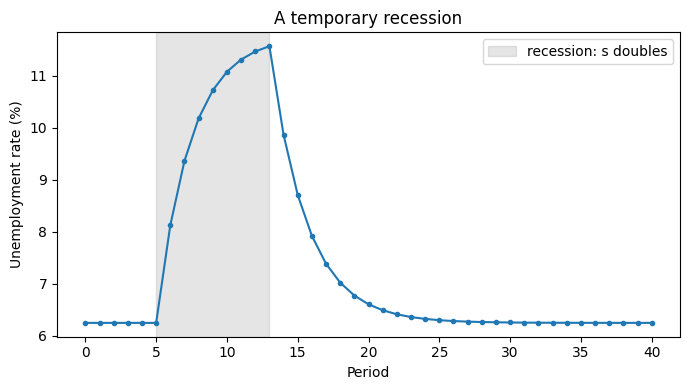

In [13]:
_ = A5.recession(s=0.02, f=0.30, s_recession=0.04, start=5, length=8, T=40)

## 6. <a id='toc6_'></a>[Optional: diversification with two stocks](#toc0_)

Two stocks have the same expected annual return $\mu=8\%$ and the same standard deviation $\sigma=20\%$, but their returns are correlated with coefficient $\eta$. The function below, which you may use as given, draws `n_worlds` pairs of returns. An equal-weighted portfolio earns $r_P=\tfrac12 r_A+\tfrac12 r_B$.

**Tasks.**
1. For $\eta=0$ and $\eta=0.5$, draw 100,000 pairs and compute the mean and standard deviation of $r_P$.
2. Is the portfolio's mean still about 8%? Is its standard deviation below 20%? Why does splitting your money help?

*Optional:* repeat for $\eta$ from $-1$ to $1$ and plot the portfolio's standard deviation against $\eta$.

In [8]:
mu = 0.08
sigma = 0.20
n_worlds = 100_000

mu = 0.08
sigma=0.20
n_worlds = 100_000

# create array of etas
etas = np.linspace(-1, 1, 20)

# this function is a more general solution taking an unspecified number of etas
def diversification_simulation(mu, sigma, n_worlds,etas,seed=2026):

    # Simulate normally distributed returns for n_worlds
    rng = np.random.default_rng(seed)
    z1 = rng.normal(size=n_worlds)
    z2 = rng.normal(size=n_worlds)

    # create stocks and diversified portfolio (using formulas above)
    ra = mu + sigma*z1
    rb = mu + sigma*(etas*z1[:, np.newaxis] + np.sqrt(1-etas**2)*z2[:, np.newaxis]) # we use newaxis to add an extra dimension to z1 and z2 so they can broadcast with etas
    rn = (ra[:, np.newaxis] + rb)/2 # again newaxis is used so ra and rb can broadcast together
    # you could also write [:,None] instead of [:, np.newaxis], they are equivalent
    
    # Compute the average return and standard deviation
    avg_return = np.mean(rn,axis=0) # axis=0 to compute average across worlds for each eta
    std_dev = np.std(rn,axis=0) # axis=0 to compute std dev across worlds for each eta
    
    return avg_return, std_dev

# this functon only takes one eta at a time
def correlated_returns(rng, eta, mu, sigma, n_worlds):
    """Returns of two stocks with mean mu, std sigma and correlation eta."""
    z1 = rng.normal(size=n_worlds)
    z2 = rng.normal(size=n_worlds)
    r_A = mu + sigma*z1
    r_B = mu + sigma*(eta*z1 + np.sqrt(1 - eta**2)*z2)
    return r_A, r_B

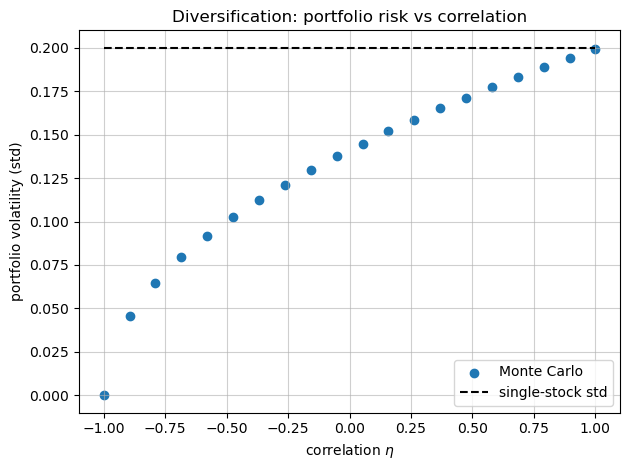

In [9]:
# use function and make the plot
diversified_avg_return, diversified_std_dev = diversification_simulation(mu, sigma, n_worlds,etas)

plt.scatter(etas, diversified_std_dev, label='Monte Carlo')
plt.plot([-1,1], [sigma, sigma], label='single-stock std', linestyle='--',c='black')
plt.xlabel('correlation ${\\eta}$')
plt.ylabel('portfolio volatility (std)')
plt.title('Diversification: portfolio risk vs correlation')
plt.grid(True, alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
import A6
A6.run(mu=mu, sigma=sigma, n_worlds=n_worlds, seed=2026)
# optional: A6.sweep(mu=mu, sigma=sigma, n_worlds=n_worlds, seed=2026)

single stock:  mean = 0.0800, std = 0.2000
eta = 0.0:     portfolio mean = 0.0802, std = 0.1412
eta = 0.5:     portfolio mean = 0.0803, std = 0.1736
